# Laboratorio 10 — EMG del abductor corto del pulgar en reposo

**Análisis individual del registro de reposo**  
Curso: Introducción a las Señales Biomédicas  
Registro: `opensignals_0C4314247FC7_2026-09-04_15-31-16(2).txt`

## Alcance del trabajo
Se analizó el registro identificado por el grupo como abductor pollicis brevis en reposo. Esta identificación corresponde a la información del experimento; la cabecera del archivo no especifica el músculo ni la condición. El TXT original está incorporado en el cuaderno para poder ejecutarlo sin depender de una ruta de Drive.

Nuestro objetivo en esta parte fue caracterizar la señal de fondo, revisar su calidad y obtener características que después puedan compararse con movimiento leve y esfuerzo máximo. No se usaron los datos del brazo del solucionario ni se generaron contracciones simuladas. Las variaciones de amplitud dentro de este archivo no se etiquetaron como contracciones sin una referencia experimental.


## 0. Configuración y carga del registro
Se utilizaron las mismas herramientas de procesamiento del laboratorio. La celda siguiente recupera el TXT incorporado y lee sus metadatos.

In [1]:
import base64, zlib, json, io
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.stats import kurtosis, skew
try:
    from IPython.display import display
except ImportError:
    display = print
np.random.seed(42)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.25})
NOMBRE_ARCHIVO = "opensignals_0C4314247FC7_2026-09-04_15-31-16(2).txt"
DATOS_COMPRIMIDOS = '...'
texto = zlib.decompress(base64.b64decode(DATOS_COMPRIMIDOS)).decode()
meta = next(iter(json.loads(texto.splitlines()[1].lstrip("# ")).values()))
datos = np.loadtxt(io.StringIO(texto), comments="#")
col = meta["column"].index("A1")
adc = datos[:, col]
FS = int(meta["sampling rate"])
BITS = int(meta["resolution"][col])
emg_mV = ((adc / 2**BITS) - 0.5) * 3.3 / 1009 * 1000
t = np.arange(len(adc)) / FS
print("Registro real incorporado:", NOMBRE_ARCHIVO)
print("Condición experimental declarada: pulgar en reposo")
print("Muestras:", len(adc), "| Fs:", FS, "Hz | Resolución:", BITS, "bits")
print("Duración:", len(adc)/FS, "s | ADC mínimo/máximo:", adc.min(), adc.max())


Registro real incorporado: opensignals_0C4314247FC7_2026-09-04_15-31-16(2).txt
Condición experimental declarada: pulgar en reposo
Muestras: 27900 | Fs: 1000 Hz | Resolución: 10 bits
Duración: 27.9 s | ADC mínimo/máximo: 479.0 547.0


## 1. Fundamentos fisiológicos — preguntas de verificación

**1. Con una unidad motora, ¿se distingue cada descarga? ¿Y con sesenta?**
En la simulación didáctica de la guía, con una unidad motora se distinguen las descargas porque aparecen separadas. Con sesenta, los potenciales se superponen y forman un patrón de interferencia. Esta comparación corresponde al modelo de la guía; el registro de superficie de nuestro pulgar no permite contar directamente cuántas unidades motoras participan.

**2. ¿Qué representa pasar de cinco a sesenta unidades?**
Representa el reclutamiento de unidades motoras. Se incorporan más unidades a la actividad muscular para responder a una mayor demanda de fuerza. En nuestro archivo no se realizó una comparación de fuerza, porque la condición registrada fue reposo.

**3. ¿Por qué una señal que parece ruido sigue siendo útil?**
Porque su amplitud y su distribución en frecuencia pueden resumirse mediante características. El RMS, por ejemplo, permite describir la amplitud efectiva sin separar cada potencial. En reposo estas medidas sirven para caracterizar el nivel de fondo, aunque por sí solas no indican si una variación corresponde a actividad muscular involuntaria, interferencia o movimiento.


## 2. Instrumentación, conversión y control de calidad

,Parámetro,Valor
0,Duración (s),27.900000
1,Muestreo (Hz),1000.000000
2,Resolución (bits),10.000000
3,ADC mínimo,479.000000
4,ADC máximo,547.000000
5,Paso ADC (µV),3.193911
6,Saturadas 0/1023,0.000000
7,Extremos incluyendo 1022,0.000000


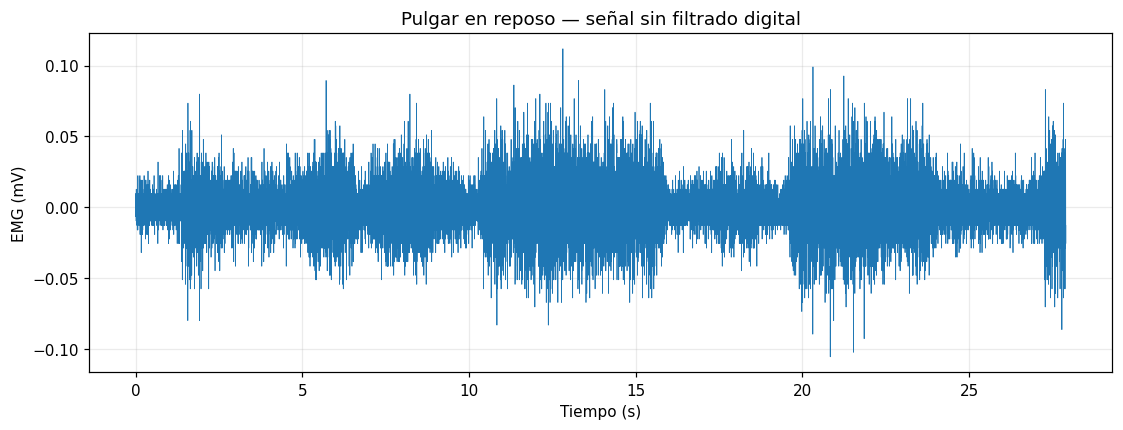

In [2]:
saturada = (adc <= 0) | (adc >= 2**BITS - 1)
cerca_limite = (adc <= 0) | (adc >= 2**BITS - 2)
resumen = pd.DataFrame({
    "Parámetro": ["Duración (s)", "Muestreo (Hz)", "Resolución (bits)", "ADC mínimo", "ADC máximo", "Paso ADC (µV)", "Saturadas 0/1023", "Extremos incluyendo 1022"],
    "Valor": [len(adc)/FS, FS, BITS, adc.min(), adc.max(), 3.3/1009/2**BITS*1e6, saturada.sum(), cerca_limite.sum()]})
display(resumen)
plt.plot(t, emg_mV, lw=0.5)
plt.xlabel("Tiempo (s)"); plt.ylabel("EMG (mV)")
plt.title("Pulgar en reposo — señal sin filtrado digital")
plt.show()


El registro contiene 27,900 muestras y dura 27.90 s. Los valores del ADC se encuentran entre 479 y 547, por lo que no alcanzan los límites del convertidor. La conversión expresa la señal en milivoltios; el desplazamiento respecto de cero se revisa posteriormente mediante el filtrado.

**1. ¿Qué porcentaje está saturado? ¿Es aceptable?**  
No se encontraron muestras en 0 ni en 1023: el porcentaje es 0 %. Tampoco se encontraron al incluir 1022. No hay evidencia de recorte en los extremos digitales con estos criterios. Esto es favorable para el análisis, pero no demuestra por sí solo que la adquisición esté libre de ruido o artefactos.

**2. ¿Qué cambiaríamos para evitar saturación?**  
En este archivo no fue necesario corregir saturación. Para futuras adquisiciones revisaríamos una contracción de prueba antes de grabar y comprobaríamos que los picos permanezcan dentro del rango. Si se superara, habría que utilizar un sistema con un rango apropiado o una menor ganancia. La ganancia nominal del sensor usado es fija; cambiar la escala de la gráfica no evita el recorte.

**3. ¿Por qué el reposo sirve como registro de ruido?**  
Permite estimar el nivel de fondo cuando no se solicita una contracción voluntaria. Incluye ruido del sistema, de la interfaz piel-electrodo y posiblemente actividad fisiológica residual. Por eso lo usamos como referencia de reposo, sin asumir que es ruido electrónico puro ni que será idéntico al de otros archivos.


## 3. Preprocesamiento y análisis espectral
Se aplicó un pasa-banda Butterworth de 20–450 Hz y un notch de 60 Hz con Q = 30. El procesamiento es fuera de línea y se realizó hacia adelante y atrás para evitar desfase.

Media sin filtrar: -0.000213 mV
RMS filtrado: 17.049 µV
Reducción de PSD en 60 Hz frente al pasa-banda: 11.87 dB


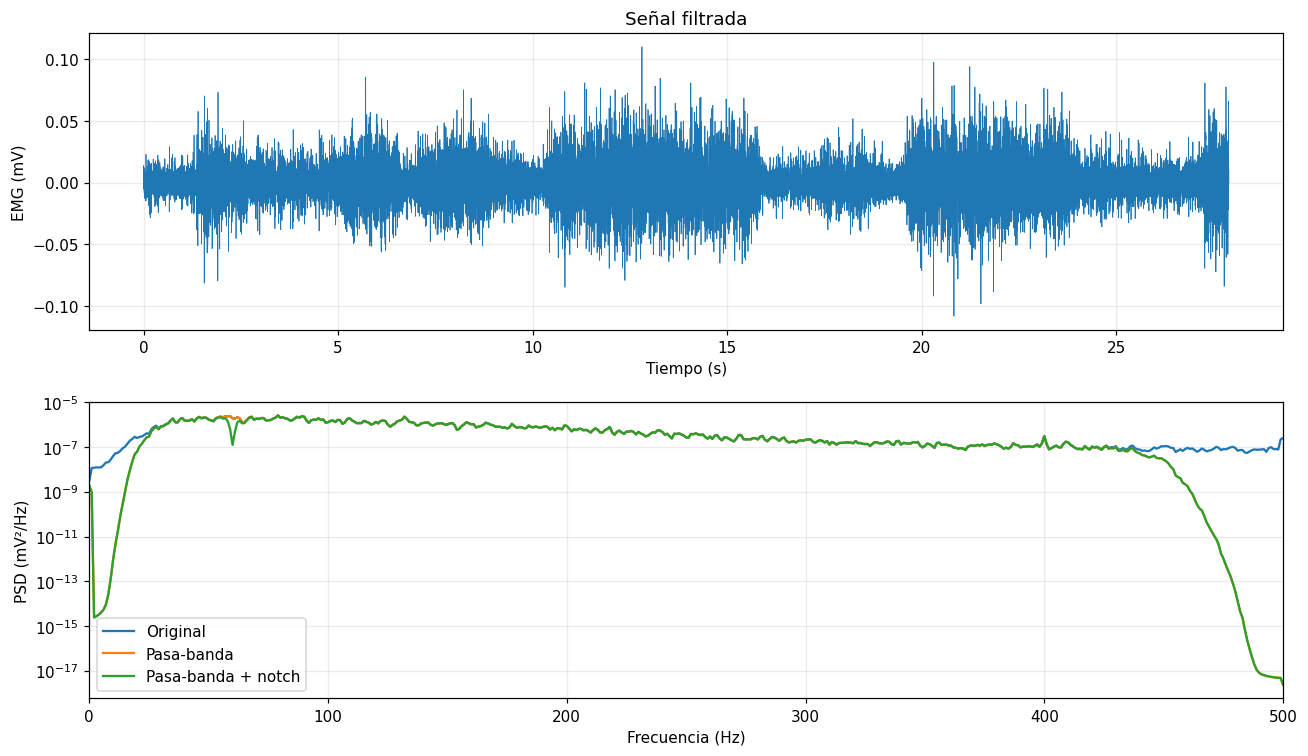

In [3]:
assert 0 < 20 < 450 < FS/2
sos = signal.butter(4, [20, 450], btype="bandpass", fs=FS, output="sos")
emg_bp = signal.sosfiltfilt(sos, emg_mV)
b, a = signal.iirnotch(60, 30, fs=FS)
emg_f = signal.filtfilt(b, a, emg_bp)
f, psd_raw = signal.welch(emg_mV, FS, nperseg=1000)
_, psd_bp = signal.welch(emg_bp, FS, nperseg=1000)
_, psd_f = signal.welch(emg_f, FS, nperseg=1000)
idx60 = np.argmin(abs(f-60))
rms_global = np.sqrt(np.mean(emg_f**2))
print(f"Media sin filtrar: {emg_mV.mean():.6f} mV")
print(f"RMS filtrado: {rms_global*1000:.3f} µV")
print(f"Reducción de PSD en 60 Hz frente al pasa-banda: {10*np.log10(psd_bp[idx60]/psd_f[idx60]):.2f} dB")
fig, ax = plt.subplots(2, 1, figsize=(12, 7))
ax[0].plot(t, emg_f, lw=.5); ax[0].set(xlabel="Tiempo (s)", ylabel="EMG (mV)", title="Señal filtrada")
for arr, label in [(psd_raw,"Original"),(psd_bp,"Pasa-banda"),(psd_f,"Pasa-banda + notch")]:
    ax[1].semilogy(f, arr, label=label)
ax[1].set(xlim=(0,500), xlabel="Frecuencia (Hz)", ylabel="PSD (mV²/Hz)")
ax[1].legend(); plt.tight_layout(); plt.show()


El RMS de la señal filtrada fue de **17.05 µV**. Lo interpretamos como amplitud efectiva del registro de reposo y no como una medida de fuerza. Las variaciones que permanecen después del filtrado deben conservarse en el análisis, ya que no contamos con anotaciones que permitan atribuirlas a una causa específica.

**1. ¿Se observa una componente de 60 Hz? ¿Qué ocurre después del notch?**  
Antes del notch, la PSD en 60 Hz equivale a 0.98 veces el promedio de los puntos 56, 57, 63 y 64 Hz del espectro pasa-banda. Después del notch, la PSD en 60 Hz se reduce 11.87 dB respecto al pasa-banda. Esto cuantifica la atenuación en esa frecuencia, sin afirmar que se haya eliminado toda la interferencia del registro.

**2. ¿En qué frecuencias se concentra la energía durante la contracción?**  
Esta pregunta no puede resolverse experimentalmente con nuestra parte, porque solo se analizó reposo. Podemos describir su espectro, pero no presentarlo como el espectro de una contracción. La comparación se completará con los archivos de movimiento leve y esfuerzo máximo.

**3. ¿Por qué no usar un pasa-bajos de 50 Hz para limpiar la EMG?**  
Porque eliminaría componentes por encima de 50 Hz que pueden formar parte de la actividad muscular. Para atenuar una interferencia localizada en 60 Hz se utiliza una muesca estrecha. Además, un pasa-bajos de 50 Hz no resuelve por sí solo los artefactos de baja frecuencia.

La SNR entre contracción y reposo no se calculó: falta una condición activa de referencia. Tampoco se estimó un porcentaje de ruido eliminado comparando directamente la señal con offset y la señal filtrada.


## 4. Segmentación y etiquetado
Se utilizaron ventanas de 250 ms con 50 % de solapamiento. La etiqueta corresponde a la condición experimental del archivo: reposo. No se crearon etiquetas de contracción a partir de fluctuaciones de este mismo registro.

Ventanas: 222 | Muestras por ventana: 250
Paso: 125 ms | Etiqueta: reposo | Sin descarte automático de ventanas


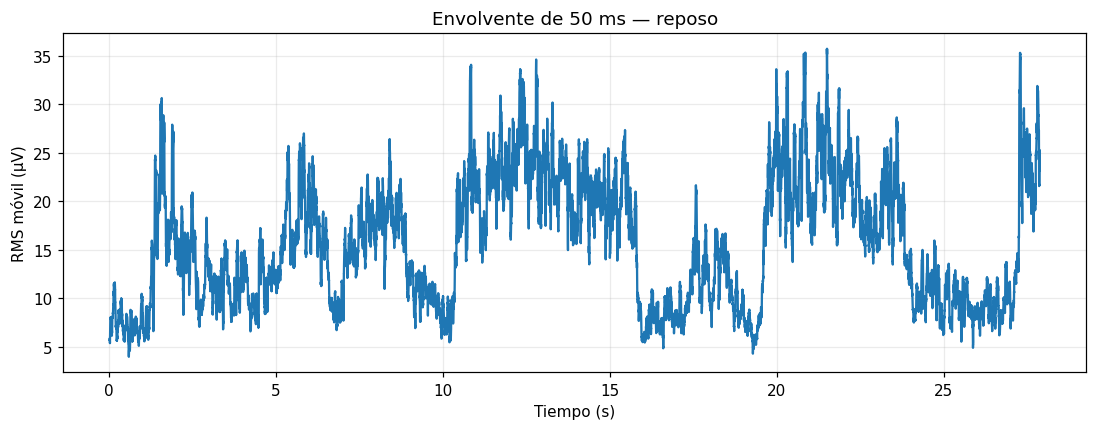

In [4]:
def crear_ventanas(x, ventana_ms=250, solap=0.5):
    n = int(round(FS*ventana_ms/1000))
    paso = max(1, int(round(n*(1-solap))))
    inicios = np.arange(0, len(x)-n+1, paso)
    return np.array([x[i:i+n] for i in inicios]), inicios
ventanas, inicios = crear_ventanas(emg_f)
env = np.sqrt(np.convolve(emg_f**2, np.ones(50)/50, mode="valid"))
te = (np.arange(len(env))+24.5)/FS
print("Ventanas:", len(ventanas), "| Muestras por ventana:", ventanas.shape[1])
print("Paso: 125 ms | Etiqueta: reposo | Sin descarte automático de ventanas")
plt.plot(te, env*1000)
plt.xlabel("Tiempo (s)"); plt.ylabel("RMS móvil (µV)"); plt.title("Envolvente de 50 ms — reposo")
plt.show()


La envolvente muestra cómo varía la amplitud dentro del registro. Un aumento de RMS no se consideró automáticamente una contracción, porque podría corresponder a movimiento, actividad residual u otros cambios de adquisición. No se estimaron ciclos de contracción ni se aplicó un umbral para generar una segunda clase artificial.

El solapamiento permite obtener una característica cada 125 ms, pero las ventanas consecutivas comparten muestras. Por tanto, su número no equivale al número de observaciones experimentales independientes. Para analizar otra condición, se deberá revisar su propio nivel de fondo antes de trasladar un umbral obtenido aquí.


## 5. Extracción de características
Se calcularon características de amplitud, forma de onda, distribución y frecuencia. La curtosis se expresa como exceso de Fisher: una distribución gaussiana tiene valor 0. ZC, SSC y WAMP usan un umbral exploratorio de tres desviaciones estándar del registro filtrado; se reporta para poder reproducir el cálculo.

Umbral ε: 51.146 µV
iEMG: suma discreta en mV, sin multiplicar por el intervalo de muestreo.


,t_inicio_s,MAV,RMS,iEMG,VAR,WL,ZC,SSC,WAMP,Asimetria,Curtosis,MNF,MDF,P_20_80,P_80_150,P_150_450,etiqueta,saturada
0,0.000,0.006343,0.008304,1.585865,0.000069,1.664732,0,0,0,-0.271498,0.886412,152.333913,117.1875,0.254158,0.386428,0.359414,reposo,False
1,0.125,0.006610,0.008695,1.652413,0.000076,1.715399,0,0,0,-0.243579,0.600002,163.125295,132.8125,0.269698,0.277467,0.452835,reposo,False
2,0.250,0.005877,0.007585,1.469373,0.000058,1.419898,0,0,0,0.135908,0.335272,116.333882,54.6875,0.615656,0.132065,0.252279,reposo,False
3,0.375,0.005332,0.006822,1.332916,0.000047,1.233118,0,0,0,0.019065,0.446078,136.587072,93.7500,0.344562,0.339378,0.316061,reposo,False
4,0.500,0.005271,0.007149,1.317648,0.000051,1.383885,0,0,0,0.667251,1.992726,160.708144,117.1875,0.307747,0.289581,0.402672,reposo,False


,mean,std,min,max
MAV,0.012444,0.004710,0.004809,0.022764
RMS,0.015952,0.005957,0.006316,0.028652
iEMG,3.111087,1.177467,1.202360,5.691100
VAR,0.000291,0.000198,0.000040,0.000824
WL,2.815666,1.042363,1.233118,4.692495
ZC,1.211712,1.850828,0.000000,8.000000
SSC,0.968468,1.718648,0.000000,9.000000
WAMP,1.527027,2.331505,0.000000,11.000000
Asimetria,0.118559,0.241332,-0.451047,0.731714
Curtosis,0.513168,0.623074,-0.446357,3.080138


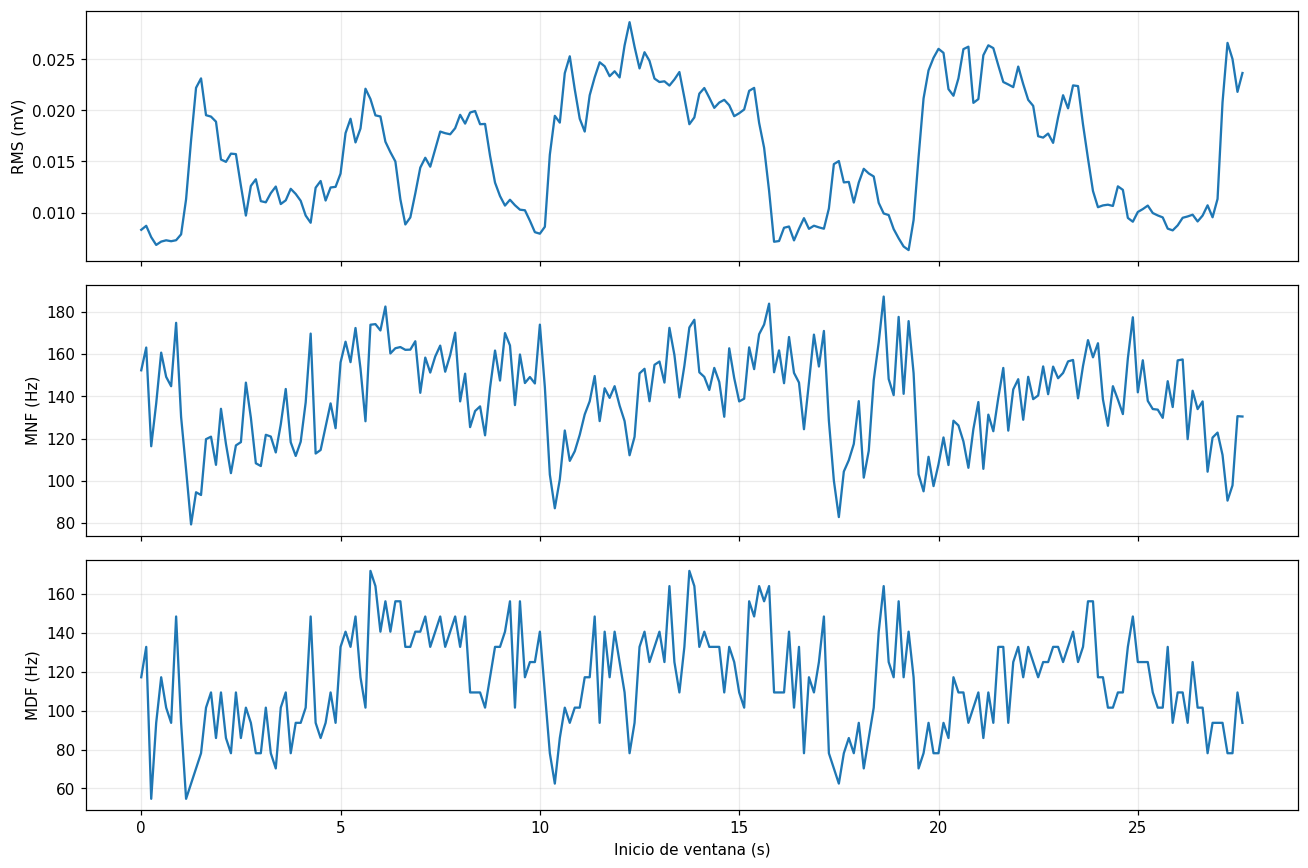

In [5]:
EPS = 3*np.std(emg_f)
def extraer(v):
    n = len(v); d = np.diff(v)
    ff, pp = signal.welch(v, FS, nperseg=min(128,n))
    m = (ff>=20)&(ff<=450); ff, pp = ff[m], pp[m]
    total = pp.sum()
    out = {"MAV":np.mean(abs(v)), "RMS":np.sqrt(np.mean(v*v)),
           "iEMG":np.sum(abs(v)), "VAR":np.var(v,ddof=1), "WL":np.sum(abs(d)),
           "ZC":np.sum((v[:-1]*v[1:]<0)&(abs(d)>=EPS)),
           "SSC":np.sum((d[:-1]*d[1:]<0)&(np.maximum(abs(d[:-1]),abs(d[1:]))>=EPS)),
           "WAMP":np.sum(abs(d)>EPS), "Asimetria":skew(v,bias=False),
           "Curtosis":kurtosis(v,fisher=True,bias=False),
           "MNF":np.sum(ff*pp)/total if total>0 else np.nan,
           "MDF":ff[np.searchsorted(np.cumsum(pp),total/2)] if total>0 else np.nan}
    for low,high in [(20,80),(80,150),(150,450)]:
        m = (ff>=low)&((ff<high) if high<450 else (ff<=high))
        out[f"P_{low}_{high}"] = pp[m].sum()/total if total>0 else np.nan
    return out
CARACTERISTICAS = list(extraer(ventanas[0]))
df = pd.DataFrame([extraer(v) for v in ventanas])
df.insert(0,"t_inicio_s",inicios/FS)
df["etiqueta"] = "reposo"
df["saturada"] = [saturada[i:i+ventanas.shape[1]].any() for i in inicios]
print(f"Umbral ε: {EPS*1000:.3f} µV")
print("iEMG: suma discreta en mV, sin multiplicar por el intervalo de muestreo.")
display(df.head())
display(df[CARACTERISTICAS].describe().T[["mean","std","min","max"]])
fig, ax = plt.subplots(3,1,figsize=(12,8),sharex=True)
for axis,col in zip(ax,["RMS","MNF","MDF"]):
    axis.plot(df.t_inicio_s,df[col]); axis.set_ylabel(col + (" (mV)" if col=="RMS" else " (Hz)"))
ax[-1].set_xlabel("Inicio de ventana (s)"); plt.tight_layout(); plt.show()


Se obtuvieron **222 ventanas y 15 características por ventana**. El RMS medio de las ventanas fue 15.95 µV, con un intervalo de 6.32 a 28.65 µV. La variación confirma que el reposo no produce una línea completamente constante. No permite identificar por sí sola la causa de cada cambio.

La MNF media por ventana fue 139.26 Hz y la MDF media fue 115.04 Hz. Estas cifras describen este registro filtrado; no se interpretan como evidencia de fatiga. La resolución espectral por ventana con `nperseg=128` es de 7.81 Hz, lo que limita los desplazamientos pequeños que pueden observarse en MDF.

**1. ¿Qué características encabezan Fisher? ¿ZC, SSC y WAMP miden solo frecuencia?**  
No se calculó un ranking de Fisher porque se necesita comparar dos clases y aquí solo hay reposo. ZC, SSC y WAMP tampoco describen frecuencia de manera aislada: sus conteos dependen de que los cambios superen ε y, por tanto, también de la amplitud y del umbral elegido.

**2. ¿Por qué pueden parecerse RMS, MAV, iEMG y VAR?**  
Todas están relacionadas con la amplitud. Con ventanas de igual tamaño, iEMG es exactamente el número de muestras multiplicado por MAV. VAR se relaciona con RMS al considerar la media de la ventana. Por eso no deben interpretarse como mediciones completamente independientes. La correlación del registro se muestra abajo.

**3. ¿Cómo cambia la curtosis con saturación?**  
No se puede cuantificar ese efecto aquí porque no se detectaron ventanas saturadas. De forma conceptual, el recorte modifica los extremos de la distribución y puede reducir la curtosis. Para comprobarlo experimentalmente harían falta ventanas afectadas y una comparación adecuada, sin confundir la intensidad de la actividad con el efecto del recorte.


In [6]:
display(df[["MAV","RMS","iEMG","VAR","WL"]].corr().round(3))


,MAV,RMS,iEMG,VAR,WL
MAV,1.000,0.998,1.000,0.987,0.941
RMS,0.998,1.000,0.998,0.989,0.937
iEMG,1.000,0.998,1.000,0.987,0.941
VAR,0.987,0.989,0.987,1.000,0.919
WL,0.941,0.937,0.941,0.919,1.000


## 6. Clasificación — alcance de esta entrega
No se entrenó LDA ni SVM con una sola clase. Dividir reposo al azar y llamar “contracción” a una parte produciría etiquetas sin respaldo experimental. La comparación se realizará cuando se integren los registros activos del grupo.

**1. ¿Bastaría un umbral RMS?** Un umbral puede servir para distinguir actividad del nivel de fondo, pero su desempeño debe evaluarse con ejemplos reales de ambas condiciones. En esta parte no se puede calcular su exactitud. Varias características pueden ayudar a distinguir patrones cuya amplitud sea parecida.

**2. ¿Hay separación sin características de amplitud?** No se pudo evaluar con reposo únicamente. Se necesita comprobar si las características espectrales y de forma cambian entre condiciones y si esas diferencias se mantienen en datos de prueba.

**3. ¿Qué ocurre al usar log(RMS) en LDA?** La transformación comprime los valores altos, pero su efecto en la clasificación no se puede medir sin una segunda clase. No se trasladaron las métricas del ejemplo a nuestro registro.

**4. ¿KFold o validación por grupos?** No se ejecutó clasificación. Al integrar los datos, se deben mantener juntas las ventanas que comparten muestras y separar repeticiones independientes. Separar por archivo tampoco resuelve la validación si cada condición tiene un único archivo, porque puede dejar una clase fuera del entrenamiento. La cantidad de repeticiones disponibles debe revisarse antes de elegir el número de pliegues.


## 7. Espectrograma y CNN
Se generó el espectrograma del reposo como representación tiempo-frecuencia. No se entrenó una CNN con una única clase.

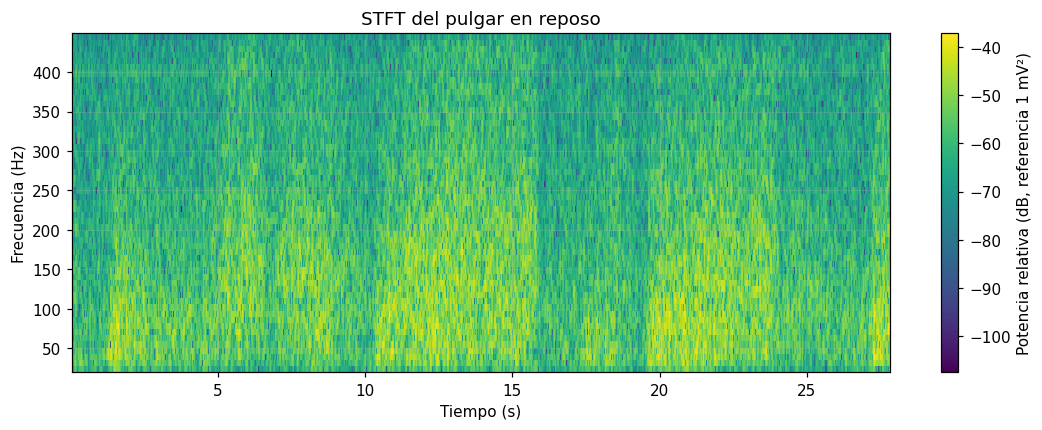

In [7]:
ff,tt,Z = signal.stft(emg_f,fs=FS,nperseg=128,noverlap=96,boundary=None,padded=False)
sel = (ff>=20)&(ff<=450)
plt.pcolormesh(tt,ff[sel],10*np.log10(np.abs(Z[sel])**2+1e-15),shading="auto",cmap="viridis")
plt.xlabel("Tiempo (s)"); plt.ylabel("Frecuencia (Hz)"); plt.title("STFT del pulgar en reposo")
plt.colorbar(label="Potencia relativa (dB, referencia 1 mV²)"); plt.show()


El espectrograma permite localizar cambios de potencia en el tiempo y la frecuencia. Las zonas más intensas representan mayor potencia dentro de la escala utilizada, pero no demuestran por sí mismas una contracción ni una emoción.

**1. ¿La CNN superó al LDA?** No se realizó esa comparación porque falta la clase activa. No corresponde reportar una exactitud con este registro aislado.

**2. ¿Qué ocurriría al probar en otra persona?** No puede establecerse con estos datos. Sería necesario adquirir registros de varios participantes y reservar sujetos completos para la evaluación, porque la anatomía, el contacto y la colocación de electrodos pueden cambiar la señal.

**3. ¿Qué ventaja y desventaja tendría una 1D-CNN?** Puede trabajar directamente con las ventanas sin convertirlas a espectrogramas. A cambio, debe aprender los patrones relevantes desde la señal y necesita suficientes ejemplos independientes. La cantidad de ventanas solapadas no sustituye la diversidad de registros.


## 8. Ejercicios adaptados al registro de reposo
### Ejercicio 1 — Tamaño de ventana
Se repitió la extracción con 100, 250 y 500 ms. Se reportan estadísticas descriptivas, no Fisher ni clasificación, porque solo se dispone de una condición.

In [8]:
filas = []
for vm in [100,250,500]:
    w, ini = crear_ventanas(emg_f,vm)
    dd = pd.DataFrame([extraer(v) for v in w])
    filas.append({"Ventana_ms":vm,"N_ventanas":len(w),
                  "RMS_medio_uV":dd.RMS.mean()*1000,"ZC_medio":dd.ZC.mean(),
                  "Curtosis_media":dd.Curtosis.mean(),"MDF_media_Hz":dd.MDF.mean(),
                  "Fisher":"No calculable: una clase","LDA":"No evaluable: una clase"})
tabla_tamanos = pd.DataFrame(filas)
display(tabla_tamanos)


,Ventana_ms,N_ventanas,RMS_medio_uV,ZC_medio,Curtosis_media,MDF_media_Hz,Fisher,LDA
0,100,557,15.871997,0.477558,0.361004,119.066427,No calculable: una clase,No evaluable: una clase
1,250,222,15.951980,1.211712,0.513168,115.040822,No calculable: una clase,No evaluable: una clase
2,500,110,16.017284,2.427273,0.655479,114.346591,No calculable: una clase,No evaluable: una clase


**Conclusión del ejercicio 1**

Se compararon ventanas de 100, 250 y 500 ms sobre el mismo registro de reposo.  
Al aumentar el tamaño disminuye el número de ventanas y cambia el detalle temporal del análisis.  
Los promedios obtenidos describen la variabilidad del reposo, no la separación frente a una contracción.  
Además, ZC es un conteo por ventana y no debe compararse entre tamaños como si fuera una tasa por segundo.  
No se calculó Fisher ni se eligieron las tres mejores características, porque falta una segunda clase.  
Tampoco se evaluó LDA con estos datos aislados.  
Como no se detectó saturación, excluir ventanas saturadas no cambia el conjunto analizado.  
La parte comparativa del ejercicio se completará al integrar las condiciones activas.

### Ejercicio 2 — Fatiga
No se calculó una tendencia por número de contracción porque este archivo fue registrado como reposo y no contiene contracciones voluntarias anotadas. Una pendiente del RMS o MDF a lo largo del tiempo no sustituye el análisis por contracciones solicitado en la guía.

Por tanto, no podemos afirmar presencia ni ausencia de fatiga con esta parte. Para evaluarla se requiere una tarea activa apropiada, control del esfuerzo y repeticiones o contracción sostenida con duración suficiente. La comparación entre movimiento leve y máximo, por sí sola, tampoco equivale a un protocolo de fatiga.

El entrenamiento opcional de CNN con ventanas de 250 ms queda fuera del análisis individual por la misma limitación de una sola clase.


## 9. Cierre y síntesis
El registro de reposo del abductor corto del pulgar tuvo una duración de 27.90 s, con muestreo de 1000 Hz y resolución de 10 bits. No se encontraron muestras en los extremos del ADC. Después del procesamiento, el RMS global fue 17.05 µV. Estos resultados permiten caracterizar el nivel de fondo de esta adquisición y dejan una referencia para la comparación con los registros activos.

La señal presentó variaciones de amplitud dentro del reposo. No se atribuyeron a una causa específica porque no contamos con marcas temporales que permitan distinguir actividad involuntaria, movimiento o interferencias. El análisis se mantuvo descriptivo y no se utilizaron fluctuaciones del propio reposo para fabricar una clase de contracción.

**¿Qué características usaríamos para una prótesis con decisión menor de 300 ms?**  
Consideraríamos características rápidas de calcular, como RMS, MAV, WL y conteos temporales, con ventanas cortas. Su capacidad de respuesta y discriminación tendría que medirse con registros activos; este archivo solo aporta el nivel de fondo. El filtrado de fase cero empleado aquí es fuera de línea y no se trasladaría directamente a una prótesis en tiempo real.

**¿Qué cambiaría con varios canales?**  
Se extraerían características de cada canal sincronizado para representar la activación de varios músculos. Nuestros archivos de músculos registrados por separado no constituyen una adquisición multicanal simultánea.

**¿Qué se necesita para funcionar en otra persona?**  
Registros de varios sujetos, condiciones de adquisición comparables y evaluación con participantes no utilizados para entrenar. Con una sola adquisición no se puede medir esa generalización.

### Entregables de esta parte
Cuaderno ejecutado, gráficas, respuestas adaptadas al reposo y matriz de características en CSV. La clasificación, la separación entre condiciones y la evaluación de fatiga no se presentan como resultados resueltos con este registro aislado.

### Referencias del material de clase
- De Luca, C. J. (1997). *The use of surface electromyography in biomechanics*. Journal of Applied Biomechanics, 13(2), 135–163.
- Hermens, H. J., et al. (2000). *Development of recommendations for SEMG sensors and sensor placement procedures*. Journal of Electromyography and Kinesiology, 10(5), 361–374.
- Hudgins, B., Parker, P., y Scott, R. N. (1993). *A new strategy for multifunction myoelectric control*. IEEE Transactions on Biomedical Engineering, 40(1), 82–94.
- Guía del Laboratorio 10 y fórmula de conversión del sensor EMG BITalino proporcionadas en el curso.


In [9]:
df.to_csv("caracteristicas_emg_pulgar_reposo.csv", index=False)
tabla_tamanos.to_csv("comparacion_ventanas_reposo.csv", index=False)
print("CSV generado: caracteristicas_emg_pulgar_reposo.csv")
print("Dimensiones:", df.shape)
# En Colab, ejecutar estas líneas si se desea descargar el CSV:
# from google.colab import files
# files.download("caracteristicas_emg_pulgar_reposo.csv")


CSV generado: caracteristicas_emg_pulgar_reposo.csv
Dimensiones: (222, 18)
